In [1]:
!pip install -q imbalanced-learn xgboost

import io
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
uploaded = files.upload()

Saving Telco-Customer-Churn dataset.csv to Telco-Customer-Churn dataset.csv


In [3]:
# Dynamically grab the uploaded filename
filename = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print(f"\nLoaded '{filename}' with shape: {df.shape}")
display(df.head())


Loaded 'Telco-Customer-Churn dataset.csv' with shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# 1. Drop customerID as it has no predictive power
if 'customerID' in df.columns:
    df = df.drop(columns=['customerID'])

# 2. Convert TotalCharges to numeric (coercing blank spaces to NaN) and handle nulls
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(f"Missing values in TotalCharges before imputation: {df['TotalCharges'].isnull().sum()}")

# Customers with NaN TotalCharges have tenure == 0, so filling with 0 is exact
df['TotalCharges'] = df['TotalCharges'].fillna(0.0)
print(f"Missing values in TotalCharges after imputation:  {df['TotalCharges'].isnull().sum()}")

# 3. Encode target variable 'Churn' (Yes -> 1, No -> 0)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Check class imbalance
print("\nTarget Class Distribution:")
print(df['Churn'].value_counts(normalize=True).round(4) * 100)

# 4. Separate Features (X) and Target (y)
X = df.drop(columns=['Churn'])
y = df['Churn']

# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f"\nNumerical columns ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")

Missing values in TotalCharges before imputation: 11
Missing values in TotalCharges after imputation:  0

Target Class Distribution:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

Numerical columns (4): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [5]:
# Stratified 80/20 train-test split to preserve original churn ratio in test evaluation
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Preprocessor: Scale numeric features and One-Hot Encode categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# Build Pipeline 1: Random Forest + SMOTE
rf_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=4,
        random_state=42,
        n_jobs=-1
    ))
])

# Build Pipeline 2: XGBoost + SMOTE
xgb_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ))
])

print("Pipelines constructed successfully!")

Pipelines constructed successfully!


In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 5-Fold Cross-Validation ROC-AUC[cite: 1]
rf_cv_scores = cross_val_score(rf_pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
xgb_cv_scores = cross_val_score(xgb_pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)

print(f"Random Forest 5-Fold CV ROC-AUC: {rf_cv_scores.mean():.4f} (+/- {rf_cv_scores.std():.4f})")
print(f"XGBoost       5-Fold CV ROC-AUC: {xgb_cv_scores.mean():.4f} (+/- {xgb_cv_scores.std():.4f})")

# Fit both pipelines on the full training set
rf_pipeline.fit(X_train, y_train)
xgb_pipeline.fit(X_train, y_train)

# Predict probabilities and classes on the unseen test set
rf_probs = rf_pipeline.predict_proba(X_test)[:, 1]
xgb_probs = xgb_pipeline.predict_proba(X_test)[:, 1]

rf_preds = rf_pipeline.predict(X_test)
xgb_preds = xgb_pipeline.predict(X_test)

rf_test_auc = roc_auc_score(y_test, rf_probs)
xgb_test_auc = roc_auc_score(y_test, xgb_probs)

print("-" * 50)
print(f"Test Set ROC-AUC (Random Forest): {rf_test_auc:.4f} ({rf_test_auc*100:.2f}%)")
print(f"Test Set ROC-AUC (XGBoost):       {xgb_test_auc:.4f} ({xgb_test_auc*100:.2f}%)")
print("-" * 50)

print("\nXGBoost Classification Report (Test Set):")
print(classification_report(y_test, xgb_preds, target_names=['No Churn (0)', 'Churn (1)']))

Random Forest 5-Fold CV ROC-AUC: 0.8445 (+/- 0.0097)
XGBoost       5-Fold CV ROC-AUC: 0.8456 (+/- 0.0102)
--------------------------------------------------
Test Set ROC-AUC (Random Forest): 0.8391 (83.91%)
Test Set ROC-AUC (XGBoost):       0.8415 (84.15%)
--------------------------------------------------

XGBoost Classification Report (Test Set):
              precision    recall  f1-score   support

No Churn (0)       0.87      0.83      0.85      1035
   Churn (1)       0.58      0.64      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409



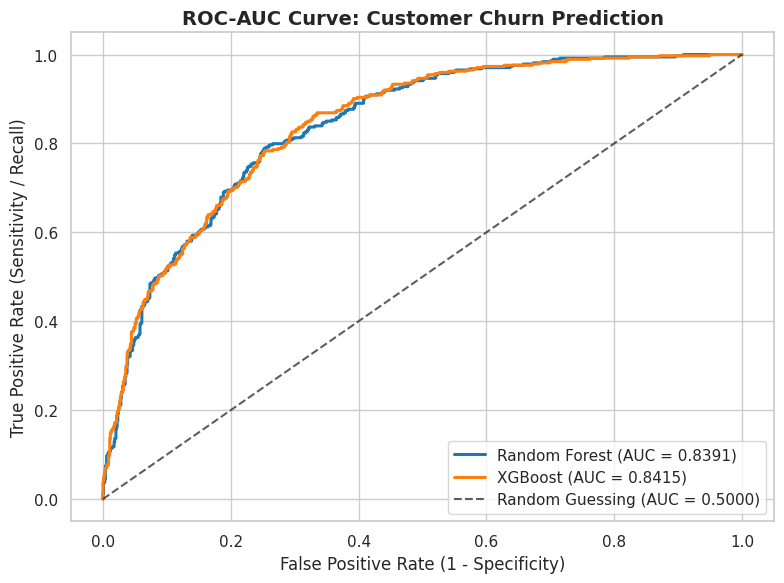

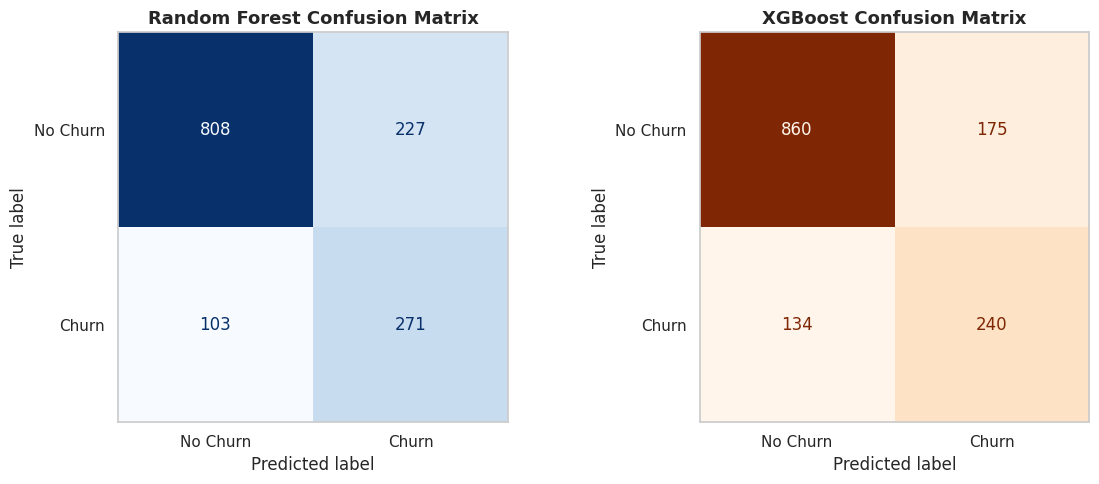

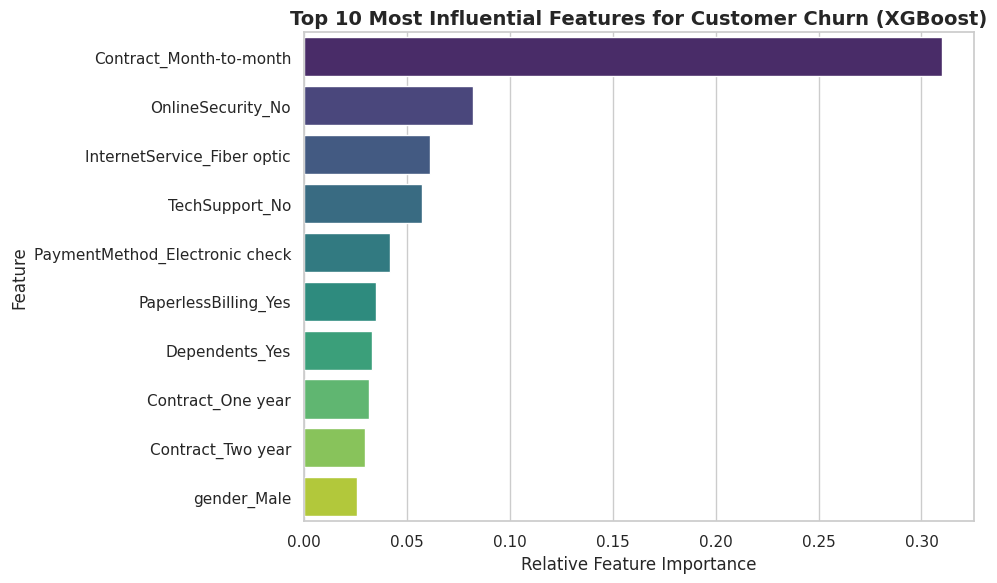


Top 10 Features Table:


,Feature,Importance
0,Contract_Month-to-month,0.310035
1,OnlineSecurity_No,0.082167
2,InternetService_Fiber optic,0.060992
3,TechSupport_No,0.057267
4,PaymentMethod_Electronic check,0.041729
5,PaperlessBilling_Yes,0.034669
6,Dependents_Yes,0.033065
7,Contract_One year,0.031627
8,Contract_Two year,0.029473
9,gender_Male,0.025646


In [7]:
# --- 1. Plot ROC-AUC Curves ---[cite: 1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_probs)

plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {rf_test_auc:.4f})', linewidth=2.2, color='#1f77b4')
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {xgb_test_auc:.4f})', linewidth=2.2, color='#ff7f0e')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing (AUC = 0.5000)', alpha=0.7)

plt.title('ROC-AUC Curve: Customer Churn Prediction', fontsize=14, fontweight='bold')
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()

# --- 2. Plot Confusion Matrices ---[cite: 1]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf = confusion_matrix(y_test, rf_preds)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['No Churn', 'Churn'])
disp_rf.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Random Forest Confusion Matrix', fontsize=13, fontweight='bold')
axes[0].grid(False)

cm_xgb = confusion_matrix(y_test, xgb_preds)
disp_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=['No Churn', 'Churn'])
disp_xgb.plot(ax=axes[1], cmap='Oranges', colorbar=False)
axes[1].set_title('XGBoost Confusion Matrix', fontsize=13, fontweight='bold')
axes[1].grid(False)

plt.tight_layout()
plt.show()

# --- 3. Extract & Plot Top 10 Feature Importances ---[cite: 1]
# Retrieve transformed feature names from ColumnTransformer
fitted_preprocessor = xgb_pipeline.named_steps['preprocessor']
ohe_feature_names = fitted_preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols)
all_feature_names = numerical_cols + list(ohe_feature_names)

# Get importances from the best performing model (XGBoost)
importances = xgb_pipeline.named_steps['classifier'].feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=feat_imp_df,
    x='Importance',
    y='Feature',
    palette='viridis'
)
plt.title('Top 10 Most Influential Features for Customer Churn (XGBoost)', fontsize=14, fontweight='bold')
plt.xlabel('Relative Feature Importance', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

print("\nTop 10 Features Table:")
display(feat_imp_df.reset_index(drop=True))

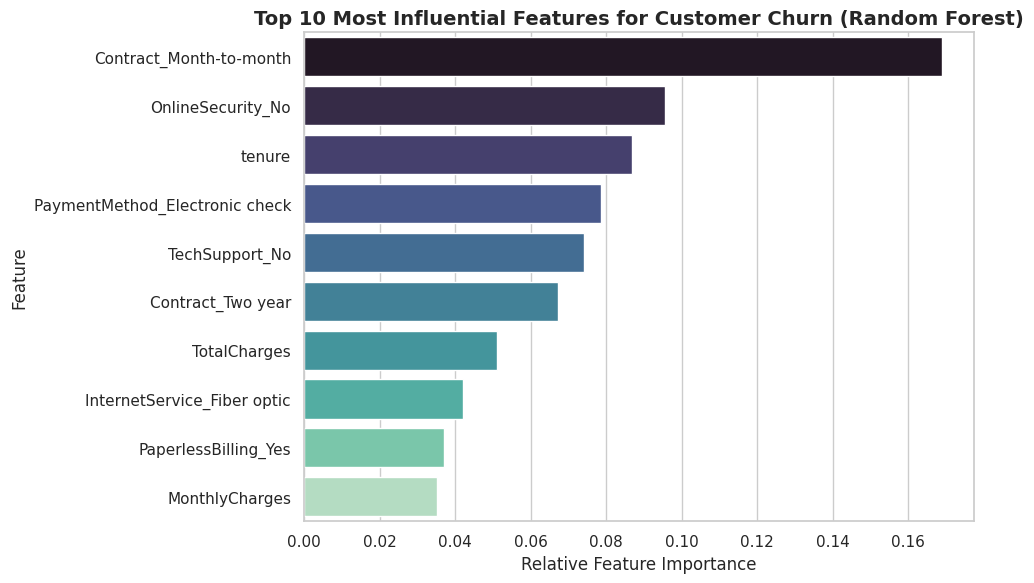

In [8]:
# Optional: Top 10 Feature Importances for Random Forest
rf_importances = rf_pipeline.named_steps['classifier'].feature_importances_
rf_feat_imp_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': rf_importances
}).sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=rf_feat_imp_df, x='Importance', y='Feature', palette='mako')
plt.title('Top 10 Most Influential Features for Customer Churn (Random Forest)', fontsize=14, fontweight='bold')
plt.xlabel('Relative Feature Importance', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()